# ROC Curves and AUC

This notebook plots ROC curves and AUC for several classifiers, shows how the decision threshold moves along the curve, and extends ROC to the multiclass one-vs-rest setting.

## Import Required Libraries

Import classifiers, datasets and ROC utilities.

In [1]:
# Import the required libraries.
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification, load_iris
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import label_binarize
from sklearn.multiclass import OneVsRestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, auc, roc_auc_score

# Define the course colour palette.
colors = ["#179E86", "#2580B7", "#9EBE5B",
          "#C03B26", "#44546A", "#F59B11"]
np.random.seed(42)

## Generate and Split the Data

Create a binary problem and hold out a test set.

In [2]:
# Generate a binary classification dataset.
X, y = make_classification(
    n_samples=1000, n_features=10, n_informative=5,
    n_classes=2, random_state=42
)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

## Train Four Classifiers

Fit a decision tree, k-NN, logistic regression and naive Bayes on the same training data.

In [3]:
# Train four different classifiers.
models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "k-NN": KNeighborsClassifier(),
    "Logistic Regression": LogisticRegression(max_iter=5000),
    "Naive Bayes": GaussianNB(),
}
for model in models.values():
    model.fit(X_train, y_train)

## Compute and Plot the ROC Curves

Plot the four ROC curves together with the random-guess diagonal and report each AUC in the legend.

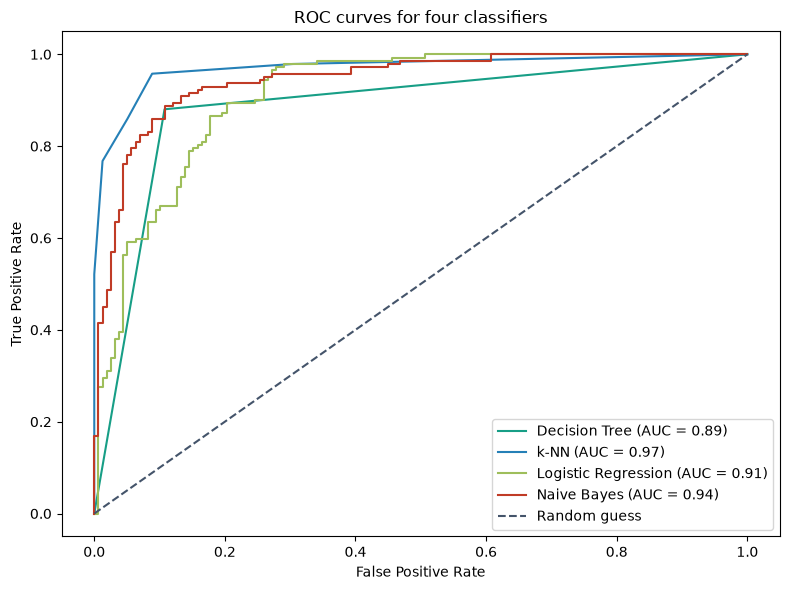

In [4]:
# Plot the ROC curve of every classifier.
fig, ax = plt.subplots(figsize=(8, 6))
for (name, model), color in zip(models.items(), colors):
    y_score = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_score)
    roc_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, color=color,
            label=f"{name} (AUC = {roc_auc:.2f})")

# Add the random-guess diagonal.
ax.plot([0, 1], [0, 1], color=colors[4], linestyle="--",
        label="Random guess")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC curves for four classifiers")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## Effect of Moving the Threshold

Each threshold on the logistic scores produces a (FPR, TPR) pair; lowering it catches more positives at the cost of more false positives.

In [5]:
# Inspect TPR and FPR at several decision thresholds.
logistic = models["Logistic Regression"]
scores = logistic.predict_proba(X_test)[:, 1]
for thr in [0.2, 0.5, 0.8]:
    pred = (scores >= thr).astype(int)
    tp = np.sum((pred == 1) & (y_test == 1))
    fp = np.sum((pred == 1) & (y_test == 0))
    fn = np.sum((pred == 0) & (y_test == 1))
    tn = np.sum((pred == 0) & (y_test == 0))
    tpr = tp / (tp + fn)
    fpr = fp / (fp + tn)
    print(f"threshold={thr}: TPR={tpr:.3f}, FPR={fpr:.3f}.")

threshold=0.2: TPR=0.986, FPR=0.430.
threshold=0.5: TPR=0.789, FPR=0.146.
threshold=0.8: TPR=0.401, FPR=0.044.


## Mark the Thresholds on the Curve

Overlay the three operating points on the logistic ROC curve.

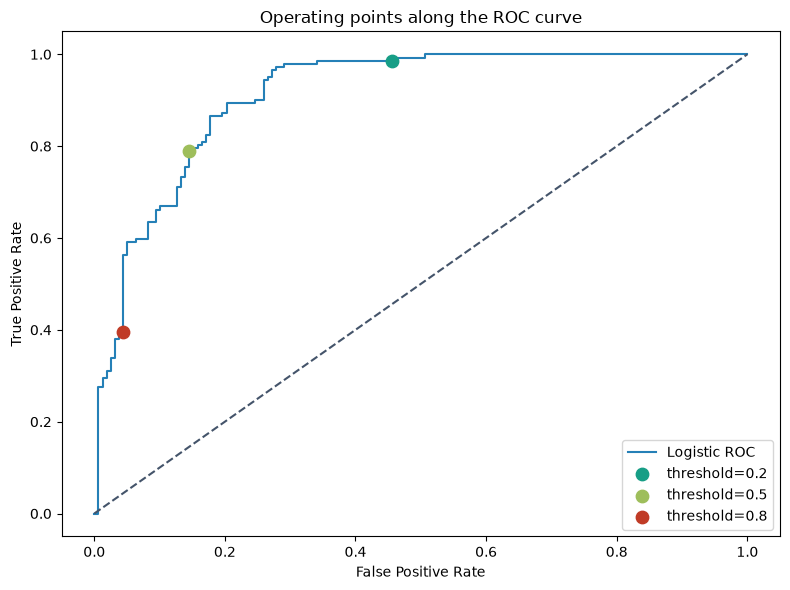

In [6]:
# Plot the ROC curve with the marked thresholds.
fpr, tpr, thresholds = roc_curve(y_test, scores)
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(fpr, tpr, color=colors[1], label="Logistic ROC")
ax.plot([0, 1], [0, 1], color=colors[4], linestyle="--")
for thr, color in zip([0.2, 0.5, 0.8], [colors[0], colors[2],
                                        colors[3]]):
    idx = np.argmin(np.abs(thresholds - thr))
    ax.scatter(fpr[idx], tpr[idx], color=color, s=80,
               zorder=5, label=f"threshold={thr}")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("Operating points along the ROC curve")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## Multiclass One-vs-Rest ROC

Binarise the iris labels and plot one ROC curve per class using the one-vs-rest scheme.

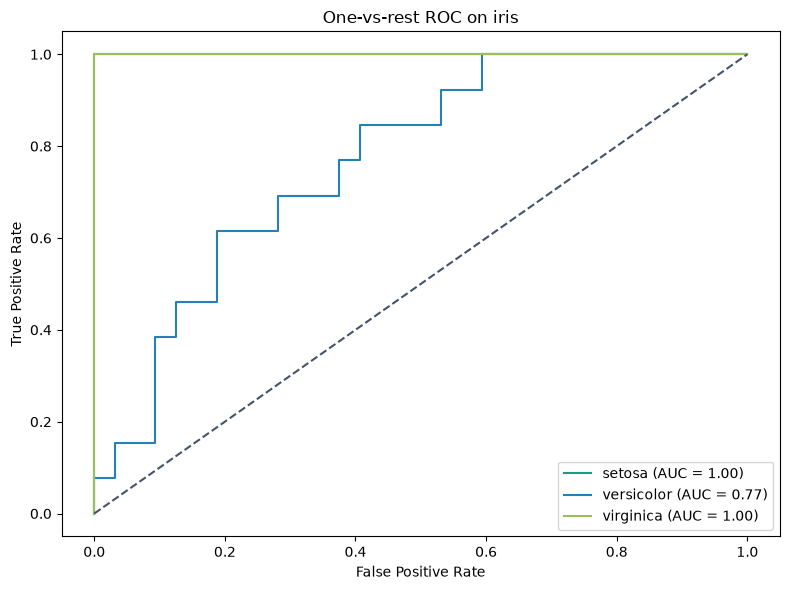

In [7]:
# Train a one-vs-rest classifier on the iris dataset.
iris = load_iris()
y_bin = label_binarize(iris.target, classes=[0, 1, 2])
Xi_tr, Xi_te, yi_tr, yi_te = train_test_split(
    iris.data, y_bin, test_size=0.3, random_state=42
)
ovr = OneVsRestClassifier(LogisticRegression(max_iter=5000))
ovr.fit(Xi_tr, yi_tr)
yi_score = ovr.predict_proba(Xi_te)

# Plot one ROC curve per class.
fig, ax = plt.subplots(figsize=(8, 6))
for i, name in enumerate(iris.target_names):
    fpr_i, tpr_i, _ = roc_curve(yi_te[:, i], yi_score[:, i])
    ax.plot(fpr_i, tpr_i, color=colors[i],
            label=f"{name} (AUC = {auc(fpr_i, tpr_i):.2f})")
ax.plot([0, 1], [0, 1], color=colors[4], linestyle="--")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("One-vs-rest ROC on iris")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## AUC Scores with roc_auc_score

`roc_auc_score` computes the AUC directly, and supports macro and weighted averaging for the multiclass case.

In [8]:
# Compute AUC scores directly with roc_auc_score.
print("Binary logistic AUC: "
      f"{roc_auc_score(y_test, scores):.4f}.")
macro_auc = roc_auc_score(yi_te, yi_score, average="macro")
weighted_auc = roc_auc_score(
    yi_te, yi_score, average="weighted"
)
print(f"Iris macro AUC:    {macro_auc:.4f}.")
print(f"Iris weighted AUC: {weighted_auc:.4f}.")

Binary logistic AUC: 0.9128.
Iris macro AUC:    0.9231.
Iris weighted AUC: 0.9333.


## Summary

- **ROC curve**: traces TPR against FPR as the decision threshold varies; the diagonal marks random guessing.
- **AUC**: summarises the curve into one number, the probability a random positive outranks a random negative.
- **Threshold**: lowering it raises TPR and FPR together; choose it to match the cost of each error type.
- **Multiclass**: one-vs-rest yields one curve per class, which `roc_auc_score` can average into a single figure.